In [2]:
path = '../../data/benchmarks/'

In [3]:
import matplotlib.pyplot as plt
import termcolor
import numpy as np
import os

In [4]:
def matrix_print(nparray, size=8):
    for x in nparray:
        for y in x:
            r = '{:+02.1f}'.format(y.real)
            i = '{:+02.1f}'.format(y.imag)
            if i not in ['+0.0', '-0.0'] or r not in ['+0.0', '-0.0']:
                r = termcolor.colored(r, 'red')
                i = termcolor.colored(i, 'red')
            print("(", r, ",", i, ")",sep="", end="  ")
        print(end="\n\n")
def matrix_print01(nparray):
    for x in nparray:
        for y in x:
            a = int(y.real != 0.0 or y.imag != 0.0)
#             print(y.real, y.imag, a)
            if a != 0:
                print(termcolor.colored("*", "red") ,end=" ", sep="")
            else:
                print(a, end=" ", sep="")
        print()
    print("--")

In [5]:
def count_matrix(npz_file, p=False):
    zeros = 0
    non_zeros = 0
    non_zeros_on_diagonal = 0
    mat = np.load(path + npz_file)["arr_0"]
    if p:
        matrix_print01(mat)
    for i in range(len(mat)):
        for j in range(len(mat[i])):
            if mat[i][j] == 0:
                zeros += 1
            else:
                if i == j:
                    non_zeros_on_diagonal += 1
                non_zeros += 1
    return zeros, non_zeros, non_zeros_on_diagonal

In [6]:
def sparsity_ratio(npz_file):
    z, nz, nzd = count_matrix(npz_file)
#     print(z, nz)
    return z/(z + nz) * 100
def density_ratio(npz_file):
    z, nz, nzd = count_matrix(npz_file)
#     print(z, nz)
    return nz/(z + nz) * 100
def diagonal_sparsity_ratio(npz_file):
    z, nz, nzd = count_matrix(npz_file)
    return nzd/(z + nz) * 100

In [7]:
def get_sparsity_ratios(circuit_name, size):
    list_of_ratios = []
    p = path + circuit_name + '/' + str(size) + '/'
    gate_num = 1
    while True:
        try:
            list_of_ratios.append(sparsity_ratio(p + "/gate_" + str(gate_num) + ".npz"))
            gate_num += 1
        except Exception as e:
            break
    gates = [str(x) for x in range(1, gate_num)]
    return gates, list_of_ratios
def get_density_ratios(circuit_name, size):
    list_of_ratios = []
    p = path + circuit_name + '/' + str(size) + '/'
    gate_num = 1
    while True:
        try:
            list_of_ratios.append(density_ratio(p + "/gate_" + str(gate_num) + ".npz"))
            gate_num += 1
        except Exception as e:
            break
    gates = [str(x) for x in range(1, gate_num)]
    return gates, list_of_ratios

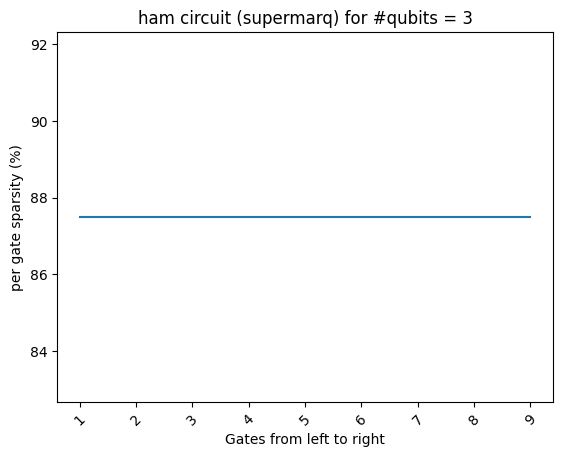

In [8]:
cir, size = 'ham', 3

x, y = get_sparsity_ratios(cir, size)
plt.plot(x, y)
plt.xticks(rotation=45)
plt.xlabel("Gates from left to right")
plt.ylabel("per gate sparsity (%)")
plt.title(cir + " circuit (supermarq) " + "for #qubits = " + str(size))
plt.show()

In [9]:
def ratiosOf(cir='ham'):
    ratios = []
    xvals = range(3, 11)
    for size in xvals:
        ratios.append(get_density_ratios(cir, size)[1][0])
    return xvals, ratios

In [10]:
xvals, ham_ratios = ratiosOf('ham')

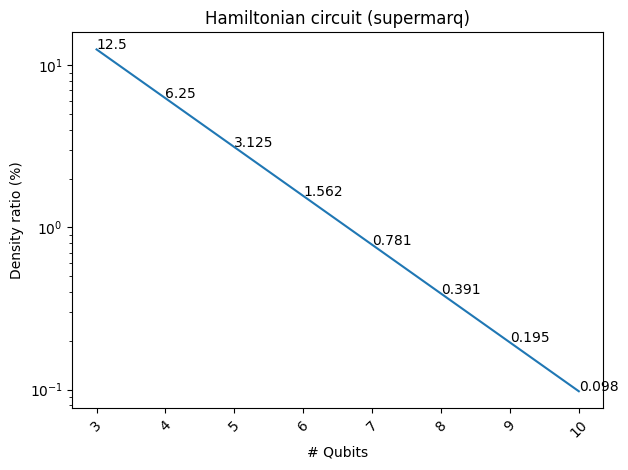

In [11]:
fig, ax = plt.subplots()

ax.set_yscale('log')

plt.plot(xvals, ham_ratios)
plt.xticks(rotation=45)
plt.xlabel("# Qubits")
plt.ylabel("Density ratio (%)")
plt.title("Hamiltonian circuit (supermarq)")
for index in range(len(xvals)):
    ax.text(xvals[index], ham_ratios[index], round(ham_ratios[index], 3))
plt.tight_layout()
plt.show()

In [12]:
xvals, mermin_ratios = ratiosOf('mermin_bell')

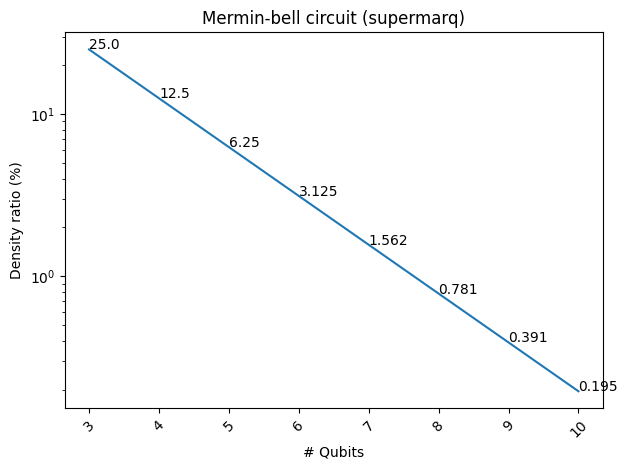

In [13]:
fig, ax = plt.subplots()

ax.set_yscale('log')

plt.plot(xvals, mermin_ratios)
plt.xticks(rotation=45)
plt.xlabel("# Qubits")
plt.ylabel("Density ratio (%)")
plt.title("Mermin-bell circuit (supermarq)")
for index in range(len(xvals)):
    ax.text(xvals[index], mermin_ratios[index], round(mermin_ratios[index], 3))
plt.tight_layout()
plt.show()

In [14]:
xvals, ghz_ratios = ratiosOf('ghz')

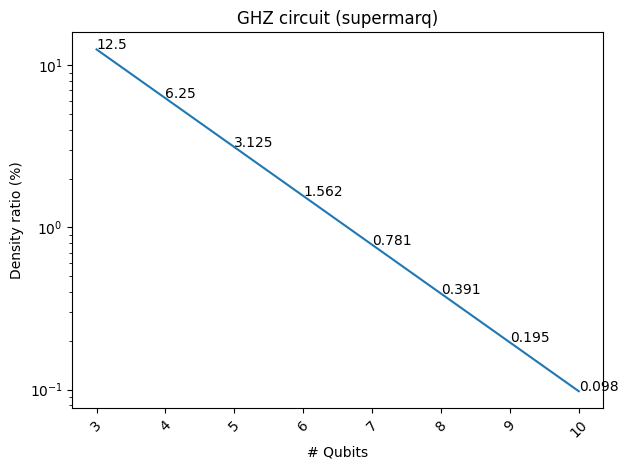

In [15]:
fig, ax = plt.subplots()

ax.set_yscale('log')

plt.plot(xvals, ghz_ratios)
plt.xticks(rotation=45)
plt.xlabel("# Qubits")
plt.ylabel("Density ratio (%)")
plt.title("GHZ circuit (supermarq)")
for index in range(len(xvals)):
    ax.text(xvals[index], ghz_ratios[index], round(ghz_ratios[index], 3))
plt.tight_layout()
plt.show()

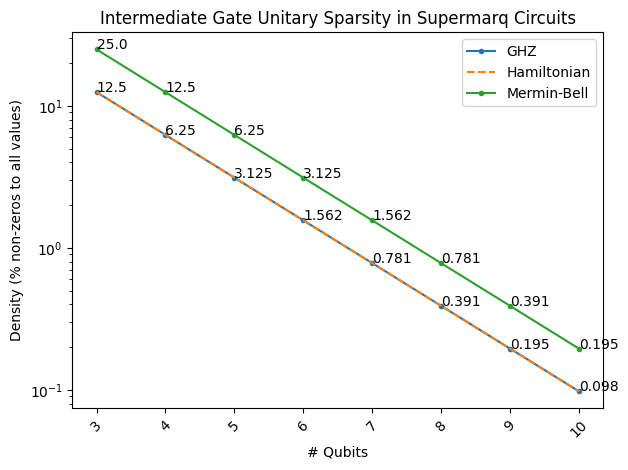

In [16]:
# all in one
fig, ax = plt.subplots()

ax.set_yscale('log')

plt.plot(xvals, ghz_ratios, label="GHZ", marker='.', linestyle='-')
plt.plot(xvals, ham_ratios, label="Hamiltonian", marker=',', linestyle='--')
for index in range(len(xvals)):
    ax.text(xvals[index], ham_ratios[index], round(ham_ratios[index], 3))
plt.plot(xvals, mermin_ratios, label="Mermin-Bell", marker='.')
for index in range(len(xvals)):
    ax.text(xvals[index], mermin_ratios[index], round(mermin_ratios[index], 3))
plt.xticks(rotation=45)
plt.xlabel("# Qubits")
plt.ylabel("Density (% non-zeros to all values)")
plt.title("Intermediate Gate Unitary Sparsity in Supermarq Circuits")
plt.tight_layout()
plt.legend()
plt.show()

In [38]:
count_matrix(path + "ghz/4/gate_1.npz", True)

* 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 
--


(240, 16, 8)

In [39]:
count_matrix(path + "ham/4/gate_2.npz", True)

* 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 
--


(240, 16, 16)

In [17]:
# new graph with left y axis as sparsity and right y axis as number of diagonals (for each gate separately)

In [18]:
# new graph with left y axis as sparsity and right y axis as number of diagonals (cummulative, after each matrix multiplication)